# Aprendizaje Automático I
## Práctica 2
Manuel Suano Gallardo

El ejercicio 10 del libro dice:

> 10. Train a deep MLP on the MNIST dataset (you can load it using tf.keras.​data⁠sets.mnist.load_data()). See if you can get over 98% accuracy by manually tuning the hyperparameters. Try searching for the optimal learning rate by using the approach presented in this chapter (i.e., by growing the learning rate exponentially, plotting the loss, and finding the point where the loss shoots up). Next, try tuning the hyperparameters using Keras Tuner with all the bells and whistles—save checkpoints, use early stopping, and plot learning curves using TensorBoard.

In [1]:
import random
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

Defino esta función para resetear la semilla para la pseudoaleatoriedad y poder tener reproducibilidad de los resultados

In [2]:
def resetear_semilla():
    random.seed(0)
    np.random.seed(0)
    tf.random.set_seed(0) 

Esta otra función para generar las gráficas de la evolución del entrenamiento. El código se ha sacado del la sección "Training and evaluating the model" del libro

In [3]:
def grafica_entrenamiento(historial, titulo):
    pd.DataFrame(historial.history).plot(
        figsize=(8, 5), xlim=[0, 29], ylim=[0, 1], grid=True, xlabel="Epoch",
        style=["r--", "r--.", "b-", "b-*"])
    plt.title(titulo)
    plt.legend(loc="lower left")  # extra code
    plt.show()

Comenzamos con la prácitca importando los datos

In [4]:
datos_mnist = tf.keras.datasets.mnist.load_data()

# Entrenamiento y prueba
(X_train_full, y_train_full), (X_test, y_test) = datos_mnist

# Separación del entrenamiento y validación
X_train, y_train = X_train_full[:-5000], y_train_full[:-5000]
X_valid, y_valid = X_train_full[-5000:], y_train_full[-5000:]

# Escalado al rango [0,1]
X_train, X_valid, X_test = X_train / 255., X_valid / 255., X_test / 255.

Definimos el tamaño de los datos de entrada al modelo. Podemos escoger cualquiera instancia del conjunto de datos, pues las dimensiones deben ser la misma en todos los casos para que sea aceptado por el modelo.

In [5]:
tamanno_entrada = X_train[0].shape

Definimos el modelo al igual que se hace en la sección "Creating the model using the Sequential API". Definiremos los dos modelos de forma manual tanto para el modelo de 3 capas como para el de 4 capas. 

El número de neuronas usado para cada capa oculta de estos modelos serán el mismo, a diferencia del modelo que se define en el libro, donde las neuronas están en forma de pirámide. La decisión de utilizar la misma cantidad de neuronas en todas las capas oculas es por lo expuesto en la sección "Number of Neurons per Hidden Layer", que indica que la práctica de escalonar el número de capas está en desuso y que incluso en algunas ocasiones se consiguen mejores resultados.

Siguiendo el ejemplo del libro, compilaremos los modelos usando SGD, con la función de pérdida "sparse_categorical_crossentropy" (ya que la salida real se trata de un entero y no una codificación) y la medición de la exactitud. El compilador por defecto tiene establecido la tasa de aprendizaje a 0.01.

In [6]:
# Restauramos las semillas para tener las mismas condiciones en cada modelo 
# y poder realizar las comparaciones
resetear_semilla()

modelo_3capas_100neuronas = tf.keras.Sequential([
	# Capa de entrada encargada de aplanar el patrón.
	tf.keras.layers.Flatten(input_shape=tamanno_entrada, name='entrada_3_100'),
	# Primera capa oculta
	tf.keras.layers.Dense(100, activation="relu", name='densa_1_3_100'),
	# Segunda capa oculta
	tf.keras.layers.Dense(100, activation="relu", name='densa_2_3_100'),
	# Tercera capa oculta
	tf.keras.layers.Dense(100, activation="relu", name='densa_3_3_100'),
	# Capa de salida. 10 neuronas, una por clase de los datos.
	tf.keras.layers.Dense(10, activation="softmax", name='salida_3_100')
], name='secuencial_3_100')

modelo_3capas_100neuronas.summary()

modelo_3capas_100neuronas.compile(
	loss="sparse_categorical_crossentropy",
	optimizer="sgd",
	metrics=["accuracy"]
)

# ###############
resetear_semilla()

modelo_3capas_300neuronas = tf.keras.Sequential([
	tf.keras.layers.Flatten(input_shape=tamanno_entrada, name='entrada_3_300'),
	tf.keras.layers.Dense(300, activation="relu", name='densa_1_3_300'),
	tf.keras.layers.Dense(300, activation="relu", name='densa_2_3_300'),
	tf.keras.layers.Dense(300, activation="relu", name='densa_3_3_300'),
	tf.keras.layers.Dense(10, activation="softmax", name='salida_3_300')
], name='secuencial_3_300')

modelo_3capas_300neuronas.summary()

modelo_3capas_300neuronas.compile(
	loss="sparse_categorical_crossentropy",
	optimizer="sgd",
	metrics=["accuracy"]
)

# ###############
resetear_semilla()

modelo_4capas_100neuronas = tf.keras.Sequential([
	tf.keras.layers.Flatten(input_shape=tamanno_entrada, name='entrada_4_100'),
	tf.keras.layers.Dense(100, activation="relu", name='densa_1_4_100'),
	tf.keras.layers.Dense(100, activation="relu", name='densa_2_4_100'),
	tf.keras.layers.Dense(100, activation="relu", name='densa_3_4_100'),
	tf.keras.layers.Dense(100, activation="relu", name='densa_4_4_100'),
	tf.keras.layers.Dense(10, activation="softmax", name='salida_4_100')
], name='secuencial_4_100')

modelo_4capas_100neuronas.summary()

modelo_4capas_100neuronas.compile(
	loss="sparse_categorical_crossentropy",
	optimizer="sgd",
	metrics=["accuracy"]
)

# ###############
resetear_semilla()

modelo_4capas_300neuronas = tf.keras.Sequential([
	tf.keras.layers.Flatten(input_shape=tamanno_entrada, name='entrada_4_300'),
	tf.keras.layers.Dense(300, activation="relu", name='densa_1_4_300'),
	tf.keras.layers.Dense(300, activation="relu", name='densa_2_4_300'),
	tf.keras.layers.Dense(300, activation="relu", name='densa_3_4_300'),
	tf.keras.layers.Dense(300, activation="relu", name='densa_4_4_300'),
	tf.keras.layers.Dense(10, activation="softmax", name='salida_4_300')
], name='secuencial_4_300')

modelo_4capas_100neuronas.summary()

modelo_4capas_300neuronas.compile(
	loss="sparse_categorical_crossentropy",
	optimizer="sgd",
	metrics=["accuracy"]
)

c:\Users\mansu\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "secuencial_3_100"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ entrada_3_100 (Flatten)         │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa_1_3_100 (Dense)           │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa_2_3_100 (Dense)           │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa_3_3_100 (Dense)           │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida_3_100 (Dense)            │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 99,710 (389.49 KB)

 Trainable params: 99,710 (389.49 KB)

...

Model: "secuencial_4_100"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ entrada_4_100 (Flatten)         │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa_1_4_100 (Dense)           │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa_2_4_100 (Dense)           │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa_3_4_100 (Dense)           │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa_4_4_100 (Dense)           │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida_4_100 (Dense)            │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,810 (428.95 KB)

 Trainable params: 109,810 (428.95 KB)

 Non-trainable params: 0 (0.00 B)

Ahora pasamos a entrenar los modelos usando los datos de entrenamiento y validación. Utilizaremos las mismas epoch que las del ejemplo del libro, aún cuando en el ejercicio resuelto las eleva a 100.

In [7]:
# De nuevo, restablecemos la semilla para poder realizar las comparaciones
resetear_semilla()

historial_3_100 = modelo_3capas_100neuronas.fit(
	X_train, y_train, epochs=30, validation_data = (X_valid, y_valid)
)

Epoch 1/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.7914 - loss: 0.7507 - val_accuracy: 0.9266 - val_loss: 0.2568
Epoch 2/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9172 - loss: 0.2859 - val_accuracy: 0.9466 - val_loss: 0.1907
Epoch 3/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9357 - loss: 0.2214 - val_accuracy: 0.9564 - val_loss: 0.1564
Epoch 4/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9468 - loss: 0.1836 - val_accuracy: 0.9620 - val_loss: 0.1361
Epoch 5/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9538 - loss: 0.1580 - val_accuracy: 0.9640 - val_loss: 0.1226
Epoch 6/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9595 - loss: 0.1389 - val_accuracy: 0.9680 - val_loss: 0.1133
Epoch 7/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9640 - loss: 0.1240 - val_accuracy: 0.9698 - val_loss: 0.1068
Epoch 8/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9677 - loss: 0.1119 - 

In [8]:
resetear_semilla()

historial_3_300 = modelo_3capas_300neuronas.fit(
	X_train, y_train, epochs=30, validation_data = (X_valid, y_valid)
)

Epoch 1/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8349 - loss: 0.6250 - val_accuracy: 0.9310 - val_loss: 0.2426
Epoch 2/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9215 - loss: 0.2706 - val_accuracy: 0.9464 - val_loss: 0.1845
Epoch 3/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9383 - loss: 0.2129 - val_accuracy: 0.9588 - val_loss: 0.1526
Epoch 4/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9483 - loss: 0.1758 - val_accuracy: 0.9632 - val_loss: 0.1324
Epoch 5/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9564 - loss: 0.1492 - val_accuracy: 0.9666 - val_loss: 0.1184
Epoch 6/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9629 - loss: 0.1290 - val_accuracy: 0.9698 - val_loss: 0.1085
Epoch 7/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9674 - loss: 0.1131 - val_accuracy: 0.9710 - val_loss: 0.1011
Epoch 8/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9711 - loss: 0.1001 - 

In [9]:
resetear_semilla()

historial_4_100 = modelo_4capas_100neuronas.fit(
	X_train, y_train, epochs=30, validation_data = (X_valid, y_valid)
)

Epoch 1/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.7607 - loss: 0.8267 - val_accuracy: 0.9260 - val_loss: 0.2680
Epoch 2/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9155 - loss: 0.2901 - val_accuracy: 0.9474 - val_loss: 0.1921
Epoch 3/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9356 - loss: 0.2196 - val_accuracy: 0.9572 - val_loss: 0.1534
Epoch 4/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9475 - loss: 0.1777 - val_accuracy: 0.9628 - val_loss: 0.1311
Epoch 5/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9562 - loss: 0.1495 - val_accuracy: 0.9674 - val_loss: 0.1167
Epoch 6/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9615 - loss: 0.1293 - val_accuracy: 0.9710 - val_loss: 0.1071
Epoch 7/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9663 - loss: 0.1139 - val_accuracy: 0.9716 - val_loss: 0.1010
Epoch 8/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9704 - loss: 0.1014 - 

In [10]:
resetear_semilla()

historial_4_300 = modelo_4capas_300neuronas.fit(
	X_train, y_train, epochs=30, validation_data = (X_valid, y_valid)
)

Epoch 1/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8234 - loss: 0.6588 - val_accuracy: 0.9336 - val_loss: 0.2297
Epoch 2/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9249 - loss: 0.2562 - val_accuracy: 0.9526 - val_loss: 0.1700
Epoch 3/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9423 - loss: 0.1947 - val_accuracy: 0.9624 - val_loss: 0.1384
Epoch 4/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9539 - loss: 0.1566 - val_accuracy: 0.9674 - val_loss: 0.1205
Epoch 5/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9622 - loss: 0.1298 - val_accuracy: 0.9690 - val_loss: 0.1091
Epoch 6/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9683 - loss: 0.1101 - val_accuracy: 0.9718 - val_loss: 0.1008
Epoch 7/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9727 - loss: 0.0947 - val_accuracy: 0.9730 - val_loss: 0.0949
Epoch 8/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9761 - loss: 0.0821 - 

Ahora pasamos a evaluar los modelos con los conjuntos test para seleccionar al mejor de los dos para cada número de capas.

In [11]:
modelo_3capas_100neuronas.evaluate(X_test, y_test)

modelo_3capas_300neuronas.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 952us/step - accuracy: 0.9745 - loss: 0.0912
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9782 - loss: 0.0755


[0.07548318803310394, 0.9782000184059143]

In [12]:
modelo_4capas_100neuronas.evaluate(X_test, y_test)

modelo_4capas_300neuronas.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 977us/step - accuracy: 0.9768 - loss: 0.0921
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9778 - loss: 0.0894


[0.08940494805574417, 0.9778000116348267]

Tras los resultados observados, para el modelo de 3 capas se selecciona el de 300 neuronas en cada capa por tener una exactitud del 97,82% en los datos de test. Para el modelo de 4 capas también se selecciona el de 300 neuronas por capa, con una exactitud sobre el conjunto de test de 97,78%.

Ahora pasamos a hacer la búsqueda de la tasa de aprendizaje óptimo. Para ello se utilizará la clase definida en el ejercicio 10 como callback a la hora de ejecutar el ajuste del modelo. Esta clase tiene un método, on_batch_end, que como su nombre indica se ejecutará tras el ajuste de cada batch. El método irá reduciendo el valor de la tasa de aprendizaje para encontrar el punto mínimo y, dado ese punto, poder escoger la tasa usado para el entramiento al completo. Según la sección "Learning Rate, Batch Size, and Other Hyperparameters", la tasa elegido debe ser un poco más pequeño que el valor que tiene cuando empieza a escalar.

In [ ]:
# Definición de la clase que se encargará de realizar el aumento de la tasa tras el entrenamiento
# de un batch de datos.
class ExponentialLearningRate(tf.keras.callbacks.Callback):
	def __init__(self, factor):
		self.factor = factor
		self.rates = []
		self.losses = []

	def on_batch_end(self, batch, logs=None):
		lr = self.model.optimizer.learning_rate.numpy() * self.factor
		self.model.optimizer.learning_rate = lr
		self.rates.append(lr)
		self.losses.append(logs["loss"])

Primero restauramos la sesión de keras

In [14]:
tf.keras.backend.clear_session()

Volvemos a definir los modelos, pero solo los de mejor resultado

In [16]:
resetear_semilla()

modelo_3capas = tf.keras.Sequential([
	tf.keras.layers.Flatten(input_shape=tamanno_entrada, name='entrada'),
	tf.keras.layers.Dense(300, activation="relu", name='densa_1'),
	tf.keras.layers.Dense(300, activation="relu", name='densa_2'),
	tf.keras.layers.Dense(300, activation="relu", name='densa_3'),
	tf.keras.layers.Dense(10, activation="softmax", name='salida')
], name='secuencial_3')

modelo_3capas.compile(
	loss="sparse_categorical_crossentropy", 
	optimizer=tf.keras.optimizers.SGD(learning_rate=1e-3),
	metrics=["accuracy"]
)

# ###############
resetear_semilla()

modelo_4capas = tf.keras.Sequential([
	tf.keras.layers.Flatten(input_shape=tamanno_entrada, name='entrada'),
	tf.keras.layers.Dense(300, activation="relu", name='densa_1'),
	tf.keras.layers.Dense(300, activation="relu", name='densa_2'),
	tf.keras.layers.Dense(300, activation="relu", name='densa_3'),
	tf.keras.layers.Dense(300, activation="relu", name='densa_4'),
	tf.keras.layers.Dense(10, activation="softmax", name='salida')
], name='secuencial_4')

modelo_4capas.compile(
	loss="sparse_categorical_crossentropy", 
	optimizer=tf.keras.optimizers.SGD(learning_rate=1e-3),
	metrics=["accuracy"]
)

c:\Users\mansu\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Entrenamos los modelos añadiendo la clase en los callbacks. Los entrenamos en solo 1 epoch ya que la tasa de aprendizaje se reduce con cada batch no con cada epoch. Se considera que ha pasado un epoch cuando se han usado todos los datos para ajustar el modelo.

In [17]:
resetear_semilla()

ratio_modelo3 = ExponentialLearningRate(factor=1.005)

historial_3 = modelo_3capas.fit(
	X_train, y_train, epochs=1, validation_data = (X_valid, y_valid), callbacks=[ratio_modelo3]
)

1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.5378 - loss: nan - val_accuracy: 0.0978 - val_loss: nan


In [18]:
resetear_semilla()

ratio_modelo4 = ExponentialLearningRate(factor=1.005)

historial_4 = modelo_4capas.fit(
	X_train, y_train, epochs=1, validation_data = (X_valid, y_valid), callbacks=[ratio_modelo4]
)

1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.5183 - loss: nan - val_accuracy: 0.0978 - val_loss: nan


Visualizando la función entre la pérdida y el logaritmo de la tasa de aprendizaje

In [19]:
def grafica_perdida_ratio(ratio_modelo):
	plt.plot(ratio_modelo.rates, ratio_modelo.losses)
	plt.gca().set_xscale('log') # Indica que la escala de X es logarítmica
	plt.hlines(min(ratio_modelo.losses), min(ratio_modelo.rates), max(ratio_modelo.rates))
	plt.axis([min(ratio_modelo.rates), max(ratio_modelo.rates), 0, ratio_modelo.losses[0]])
	plt.grid()
	plt.xlabel("Learning rate")
	plt.ylabel("Loss")

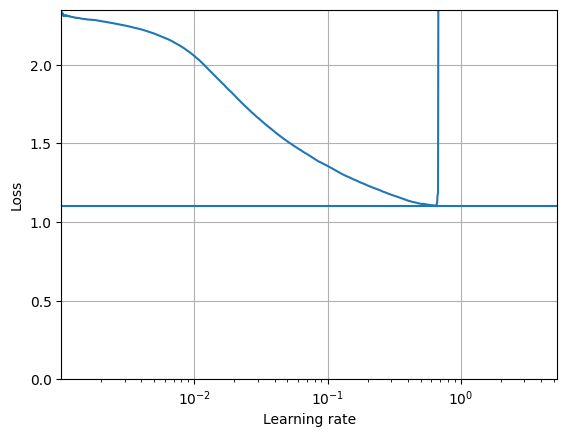

In [20]:
grafica_perdida_ratio(ratio_modelo3)

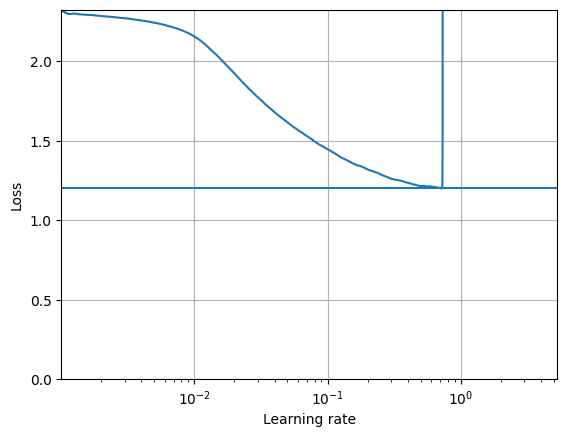

In [21]:
grafica_perdida_ratio(ratio_modelo4)

En el libro se indica que se tome un valor ligeramente inferior al valor que obtiene la tasa junto en el momento que comienza a escalar la función de pérdida, es decir, en su mínimo. Si encontramos la posición del mínimo en el array sin tener en cuenta los valores nan, podemos tomar el valor de la tasa con la misma posición. En el ejercicio del libro se usa la mitad de ese valor, por lo que aquí se hará lo mismo.

In [55]:
numpy_perdida = np.array(ratio_modelo3.losses)
pos_perdida_minima_modelo_3 = np.argmin(numpy_perdida[np.not_equal(np.isnan(numpy_perdida), True)])
ratio_seleccionado_3 = ratio_modelo3.rates[pos_perdida_minima_modelo_3] / 2

numpy_perdida = np.array(ratio_modelo4.losses)
pos_perdida_minima_modelo_4 = np.argmin(numpy_perdida[np.not_equal(np.isnan(numpy_perdida), True)])
ratio_seleccionado_4 = ratio_modelo4.rates[pos_perdida_minima_modelo_4] / 2

print(ratio_seleccionado_3, ratio_seleccionado_4)

0.3239779 0.3579617


Volvemos a entrenar con estos ratios.

In [60]:
tf.keras.backend.clear_session()
resetear_semilla()

modelo_3capas = tf.keras.Sequential([
	tf.keras.layers.Flatten(input_shape=tamanno_entrada, name='entrada'),
	tf.keras.layers.Dense(300, activation="relu", name='densa_1'),
	tf.keras.layers.Dense(300, activation="relu", name='densa_2'),
	tf.keras.layers.Dense(300, activation="relu", name='densa_3'),
	tf.keras.layers.Dense(10, activation="softmax", name='salida')
], name='secuencial_3')

modelo_3capas.compile(
	loss="sparse_categorical_crossentropy", 
	optimizer=tf.keras.optimizers.SGD(learning_rate=0.3239),
	metrics=["accuracy"]
)

# ###############
resetear_semilla()

modelo_4capas = tf.keras.Sequential([
	tf.keras.layers.Flatten(input_shape=tamanno_entrada, name='entrada'),
	tf.keras.layers.Dense(300, activation="relu", name='densa_1'),
	tf.keras.layers.Dense(300, activation="relu", name='densa_2'),
	tf.keras.layers.Dense(300, activation="relu", name='densa_3'),
	tf.keras.layers.Dense(300, activation="relu", name='densa_4'),
	tf.keras.layers.Dense(10, activation="softmax", name='salida')
], name='secuencial_4')

modelo_4capas.compile(
	loss="sparse_categorical_crossentropy", 
	optimizer=tf.keras.optimizers.SGD(learning_rate=0.3579),
	metrics=["accuracy"]
)

En este entrenamiento indicamos de nuevo los mismos epoch que teníamos antes para poder realizar la comparación, 30 epochs. Además, añadimos los callbacks de earlystopping, para evitar un sobreentrenamiento de los modelos; el de checkpoints para quedarnos ir creando checkpoints del modelo y poder mantener el mejor modelo; y el de TensorBoard para tener las curvas del aprendizaje.

In [61]:
from pathlib import Path

run_index = 1
run_logdir = Path() / "practica2_logs" / "ejecucion_{:03d}".format(run_index)

# Si no se mejora la pérdida en 20 epochs
early_stopping_cb = tf.keras.callbacks.EarlyStopping(patience=20)

# Se guardará el mejor modelo. Uno para cada modelo
checkpoint_cb_3 = tf.keras.callbacks.ModelCheckpoint("modelo_3_practica_2.keras", save_best_only=True)
checkpoint_cb_4 = tf.keras.callbacks.ModelCheckpoint("modelo_4_practica_2.keras", save_best_only=True)

tensorboard_cb = tf.keras.callbacks.TensorBoard(run_logdir)

In [62]:
resetear_semilla()

historial_3 = modelo_3capas.fit(
	X_train, y_train, epochs=30, validation_data = (X_valid, y_valid), callbacks=[checkpoint_cb_3, early_stopping_cb, tensorboard_cb]
)

Epoch 1/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9149 - loss: 0.2708 - val_accuracy: 0.9698 - val_loss: 0.0938
Epoch 2/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9689 - loss: 0.1026 - val_accuracy: 0.9698 - val_loss: 0.0999
Epoch 3/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9788 - loss: 0.0689 - val_accuracy: 0.9732 - val_loss: 0.0892
Epoch 4/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9840 - loss: 0.0518 - val_accuracy: 0.9802 - val_loss: 0.0760
Epoch 5/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9880 - loss: 0.0379 - val_accuracy: 0.9702 - val_loss: 0.1349
Epoch 6/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9895 - loss: 0.0336 - val_accuracy: 0.9728 - val_loss: 0.1218
Epoch 7/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9904 - loss: 0.0286 - val_accuracy: 0.9728 - val_loss: 0.1237
Epoch 8/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9917 - loss: 0.0256 - 

In [63]:
np.random.seed(0)
tf.random.set_seed(0)

historial_4 = modelo_4capas.fit(
	X_train, y_train, epochs=30, validation_data = (X_valid, y_valid), callbacks=[checkpoint_cb_4, early_stopping_cb, tensorboard_cb]
)

Epoch 1/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8970 - loss: 0.3345 - val_accuracy: 0.9604 - val_loss: 0.1314
Epoch 2/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9653 - loss: 0.1175 - val_accuracy: 0.9678 - val_loss: 0.1232
Epoch 3/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9755 - loss: 0.0808 - val_accuracy: 0.9736 - val_loss: 0.0870
Epoch 4/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9809 - loss: 0.0621 - val_accuracy: 0.9692 - val_loss: 0.1082
Epoch 5/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9852 - loss: 0.0486 - val_accuracy: 0.9744 - val_loss: 0.1004
Epoch 6/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9871 - loss: 0.0396 - val_accuracy: 0.9786 - val_loss: 0.0963
Epoch 7/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9897 - loss: 0.0336 - val_accuracy: 0.9776 - val_loss: 0.0987
Epoch 8/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9912 - loss: 0.0281 - 

Realizamos la evaluación de los modelos para comprobar la exactitud en los datos de test.

In [64]:
modelo_3capas.evaluate(X_test, y_test)

modelo_4capas.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9845 - loss: 0.0957
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9814 - loss: 0.1173


[0.11730384826660156, 0.9814000129699707]

### Conclusiones

Al principio hemos visto como de los 4 modelos que se han definido, en ambos casos se obtenía mejores resultados en los modelos que tenían mayor complejidad (más neuronas):
- En el caso de los modelos con 3 capas ocultas: el modelo con 300 neuronas por capa obtenía una exactitud de 97,82% mientras que el de 100 neuronas por capa obtenía un 97,45%
- En el caso de los modelos con 4 capas ocultas: el modelo con 300 neuronas por capa obtenía una exactitud de 97,78% mientras que el de 100 neuronas por capa obtenía un 97,68%

Viendo los resultados, a priori parece que entre los dos tipos de modelos (3 y 4 capas ocultas), el modelo de menor complejidad ofrece mejores resultados sobre el conjunto de test, pudiendo suponer que el segundo se está sobreajustando ligeramente más que el primero, aunque los porcentajes son muy similares como para poder afirmar esto.

Podemos ver la evolución del entrenamiento de los diferentes modelos:

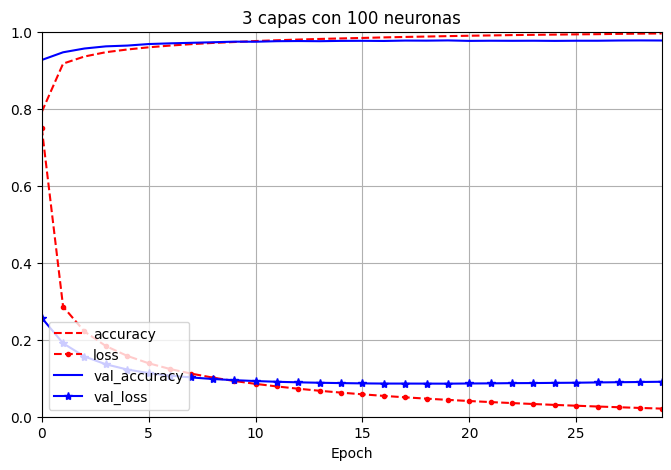

In [22]:
grafica_entrenamiento(historial_3_100, "3 capas con 100 neuronas")

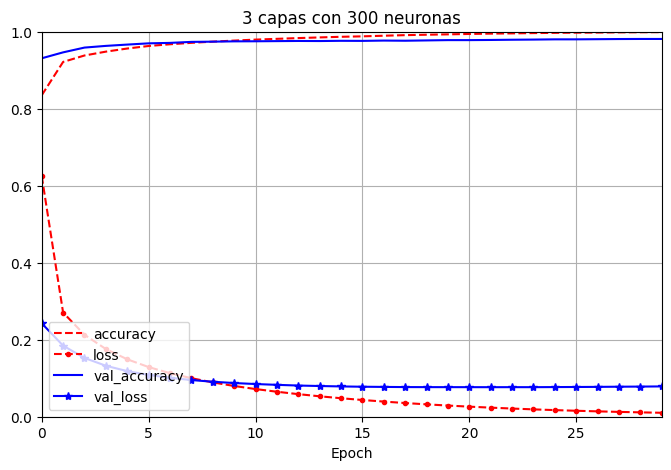

In [23]:
grafica_entrenamiento(historial_3_300, "3 capas con 300 neuronas")

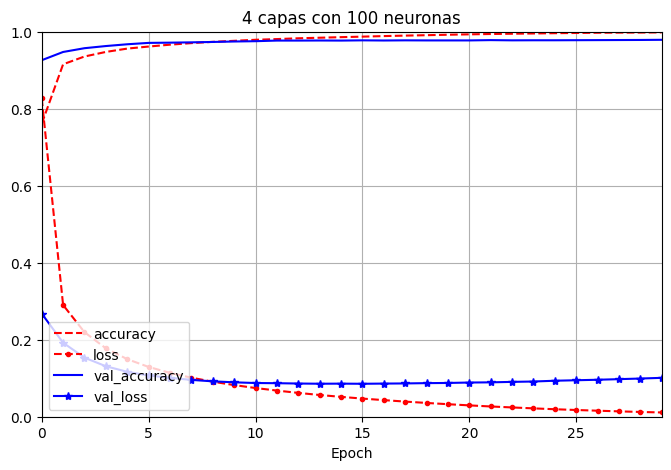

In [24]:
grafica_entrenamiento(historial_4_100, "4 capas con 100 neuronas")

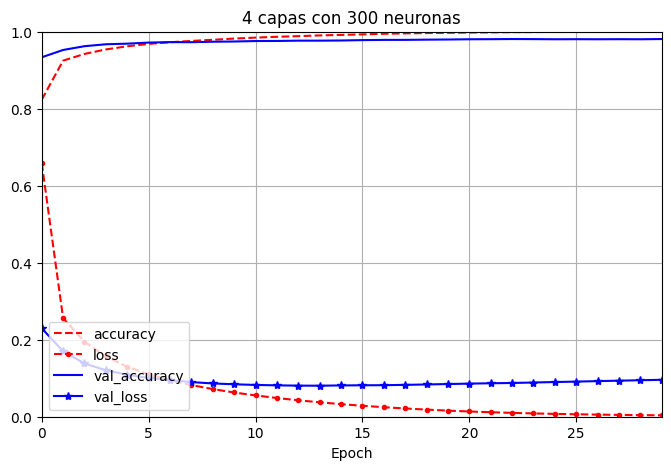

In [25]:
grafica_entrenamiento(historial_4_300, "4 capas con 300 neuronas")

En todos los modelos la exactitud del entrenamiento es casi 1, siendo en el último (4 capas con 300 neuronas) dónde más significativo se ve, pues la línea de puntos casi ni se percibe.

También se puede observar como la pérdida del conjunto de validación se convierte en estable, e incluso comienza a incrementearse. El hecho de que este valor se incremente significa que el modelo se está sobreajustando a los datos de entrenamiento. También se puede ver como la función de pérdida se va estabilizando con respecto pasa los epochs.

Por este motivo es importante realizar el último entrenamiento, tras seleccionar la tasa de aprendizaje, con la clase earlystopping, pues evita que se produzca este sobreajuste retrocediendo a un modeloa anterior.

Tras detectar la tasa de aprendizaje adecuada para cada modelo, 0.3239 para el de 3 capas ocultas y 0.3579 para el de 4 capas ocultas, y entrenando con el earlystopping con un límite de 20 epochs sin cambios significativos, se obtiene que:
- El nuevo modelo de 3 capas obtiene una exactitud del 98,45%
- El nuevo modelo de 4 capas obtiene una exactitud del 98,14%

Como podemos ver, de nuevo el de 3 capas obtiene mejores resultados que el modelo de 4 capas. Estos resultados parecen sugerir que el incremento de la complejidad en relación a las capas es inversamente proporcional a la exactitud del modelo, aunque sería necesario realizar más comparaciones con modelos más complejos y más sencillos para poder afirmalo completamente.